In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt 
from pathlib import Path

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
DATA_DIR = Path.cwd().parent / "data"
DATA_PATH = DATA_DIR / "tiny_shakespeare.txt"

text = DATA_PATH.read_text("utf-8")

print(text[:300])
print(f"Total characters in text: {len(text)}")

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us
Total characters in text: 1115394


In [4]:
chars = sorted(list(set(text)))
vocab_size = len(chars)

print("Vocab size:", vocab_size)
print(repr(''.join(chars)))

Vocab size: 65
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"


In [5]:
stoi = {s: i for i, s in enumerate(chars)}
itos = {i: s for s, i in stoi.items()}

In [6]:
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)

In [7]:
l = encode("Hi, World.")
print(l)
print(decode(l))

[20, 47, 6, 1, 35, 53, 56, 50, 42, 8]
Hi, World.


In [8]:
# Encoding the entire dataset
data = torch.tensor(encode(text), dtype=torch.long, device=device)
print(data.shape)
print(data[:100])

torch.Size([1115394])
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59], device='cuda:0')


In [9]:
### Splitting into train and val set

n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

In [10]:
# Example of how the training example will look
BLOCK_SIZE = 8
x = train_data[:BLOCK_SIZE]
y = train_data[1: BLOCK_SIZE+1]

for t in range(BLOCK_SIZE):
    context = x[:t+1]
    target = y[t]

    print(f"{context.tolist()} ---> {target}")

[18] ---> 47
[18, 47] ---> 56
[18, 47, 56] ---> 57
[18, 47, 56, 57] ---> 58
[18, 47, 56, 57, 58] ---> 1
[18, 47, 56, 57, 58, 1] ---> 15
[18, 47, 56, 57, 58, 1, 15] ---> 47
[18, 47, 56, 57, 58, 1, 15, 47] ---> 58


In [29]:
BATCH_SIZE = 4
block_size = 8
ix = torch.randint(0, len(data) - BATCH_SIZE, (BATCH_SIZE, ))
print(ix)

xb = torch.stack([train_data[i : i + block_size] for i in ix])
xb

tensor([574477, 121339, 373438,  61940])


tensor([[43, 56,  1, 52, 59, 56, 57, 43],
        [42,  0, 32, 46, 39, 58,  1, 57],
        [ 1, 37, 27, 30, 23, 10,  0, 25],
        [52, 53, 58, 47, 41, 43,  6,  0]], device='cuda:0')

In [14]:
block_size = 8
batch_size = 4


def get_batch(split, batch_size, block_size):
    data = train_data if split == "train" else val_data
    ix = torch.randint(0, len(data) - block_size, (batch_size, ))
    xb = torch.stack([data[i : i+block_size] for i in ix])
    yb = torch.stack([data[i+1 : i+block_size+1] for i in ix])

    return xb, yb


@torch.inference_mode()
def estimate_loss(model, eval_iters=100):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split, batch_size, block_size)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

xb, yb = get_batch("train", BATCH_SIZE, BLOCK_SIZE)
xb, yb

NameError: name 'BATCH_SIZE' is not defined

In [ ]:
def get_batch(split, batch_size, block_size):
    data = train_data if split == "train" else val_data
    ix = torch.randint(0, len(data) - block_size, (batch_size, ), device=device)
    offsets = torch.arange(block_size, device=device)
    xb = data[ix[:, None] + offsets]
    yb = data[ix[:, None] + offsets + 1]

    return xb, yb

## Bigram (Baseline)

In [24]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
         logits = self.token_embedding_table(idx) # (B, T, C)
         loss = None

         if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
         return logits, loss

    def generate(self, idx, max_new_token=20): # idx: (B, T)
        for _ in range(max_new_token):
            logits = self.token_embedding_table(idx) # (B, T, C)
            logits = logits[:, -1, :] # (B, C)
            probs = F.softmax(logits, dim=-1)
            new_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, new_idx), dim=-1) # (B, T+1)
        return idx


In [26]:
bigram_model = BigramLanguageModel(vocab_size).to(device)
optimizer = torch.optim.AdamW(bigram_model.parameters(), lr=1e-3)

In [27]:
# Dummy Forward Pass
logits, loss = bigram_model(xb)
logits.shape, loss

(torch.Size([4, 8, 65]), None)

In [28]:
lossi = []
max_steps = 15000
batch_size = 64
block_size = 8
eval_interval = 1000


for i in range(max_steps):
     
    if i % eval_interval == 0 or i == max_steps - 1:
        losses = estimate_loss(bigram_model)
        print(f"Step: {i:5d}/{max_steps} | Train Loss: {losses['train']:.4f} | Val Loss: {losses['val']:.4f}")

    xb, yb = get_batch("train", batch_size, block_size)
    logits, loss = bigram_model(xb, yb)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    lossi.append(loss.item())

Step:     0/15000 | Train Loss: 4.6961 | Val Loss: 4.6757
Step:  1000/15000 | Train Loss: 3.6379 | Val Loss: 3.6348
Step:  2000/15000 | Train Loss: 3.0424 | Val Loss: 3.0385
Step:  3000/15000 | Train Loss: 2.7291 | Val Loss: 2.7361
Step:  4000/15000 | Train Loss: 2.5973 | Val Loss: 2.6043
Step:  5000/15000 | Train Loss: 2.5309 | Val Loss: 2.5409
Step:  6000/15000 | Train Loss: 2.4952 | Val Loss: 2.5113
Step:  7000/15000 | Train Loss: 2.4814 | Val Loss: 2.4995
Step:  8000/15000 | Train Loss: 2.4735 | Val Loss: 2.4867
Step:  9000/15000 | Train Loss: 2.4686 | Val Loss: 2.4846
Step: 10000/15000 | Train Loss: 2.4720 | Val Loss: 2.4828
Step: 11000/15000 | Train Loss: 2.4587 | Val Loss: 2.4844
Step: 12000/15000 | Train Loss: 2.4602 | Val Loss: 2.4859
Step: 13000/15000 | Train Loss: 2.4525 | Val Loss: 2.4913
Step: 14000/15000 | Train Loss: 2.4539 | Val Loss: 2.4733
Step: 14999/15000 | Train Loss: 2.4494 | Val Loss: 2.4802


In [29]:
### Final losses
final_losses = estimate_loss(bigram_model, eval_iters=500)
train_ppl = torch.exp(torch.tensor(final_losses['train'])).item()
val_ppl = torch.exp(torch.tensor(final_losses['val'])).item()


print(f"Final Train Loss: {final_losses['train']:.4f} | Perplexity: {train_ppl:.2f}")
print(f"Final Val Loss:   {final_losses['val']:.4f} | Perplexity: {val_ppl:.2f}")

Final Train Loss: 2.4502 | Perplexity: 11.59
Final Val Loss:   2.4843 | Perplexity: 11.99


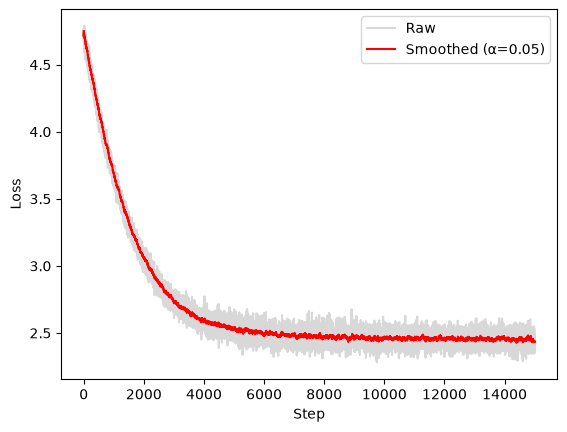

In [259]:
import pandas as pd

lossi_smoothed = pd.Series(lossi).ewm(alpha=0.05).mean()

plt.plot(lossi, color="gray", alpha=0.3, label="Raw")
plt.plot(lossi_smoothed, color="red", label="Smoothed (α=0.05)")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

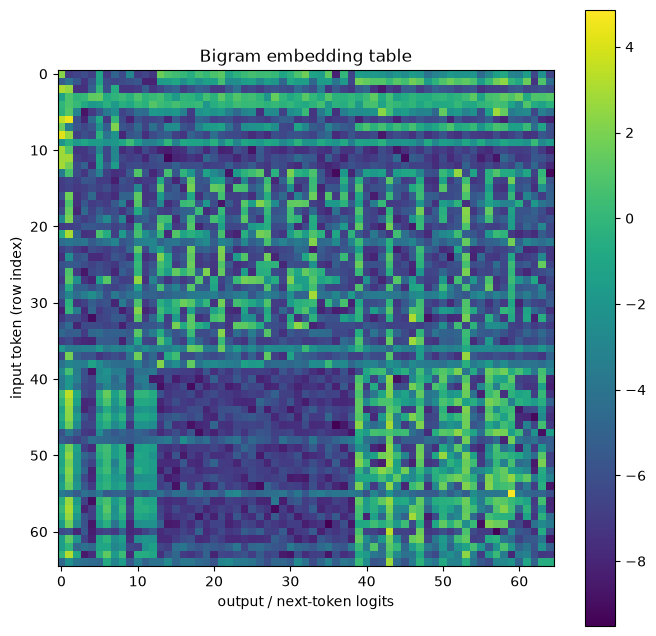

In [260]:
W = bigram_model.token_embedding_table.weight.detach().cpu().numpy()
plt.figure(figsize=(8, 8))
plt.imshow(W, cmap='viridis')
plt.colorbar()
plt.xlabel('output / next-token logits')
plt.ylabel('input token (row index)')
plt.title('Bigram embedding table')
plt.show()

In [30]:
### Text generation
idx = torch.zeros(1, 1, dtype=torch.long, device=device)
output = bigram_model.generate(idx, max_new_token=500)
print(decode(output[0].tolist()))


harplldatond t p bicend,
Y h; ANENavome rn ieatthe and ing.
SLof menty a. thisese anofff
CAn st.
To cor hem vimmend y, s haghave ou Gos ak, bllifoy.

ROry fow shithitoou nd-
Heralty prle s face tilece Hinthog;Vzet,
UCERDUKite I memicor oiut
S:
MENRDWam grese ay wored haiver mar,
t Pruist s ar, n, oued oouloworeame ende sil har'd s; as tr he le wima Ha coust S:
LO:

He the,
t e susero rand h f afot tou gitlle, aco ingt tor.
Tre p.
Ty o s,
CAuss the, or t tstsernoclf;

Thy icke w w--

Ther re t ho


## Self-attention

Mathematical  trick in self-attention

In [7]:
import torch


B, T, C = 4, 8, 2
x = torch.randn(B, T, C)
x.shape
# Currently the 8 tokens are not talking to each other and we would like to couple them.
# The easiest way to just average over the previous tokens (Information should only flow from the
# previous time step to current time step)

torch.Size([4, 8, 2])

In [ ]:
###  We want x[b, t] = mean_{i<=t} x[b, i]
xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        x_prev = x[b, :t+1] # (t, C)
        xbow[b, t] = torch.mean(x_prev, dim=0) 

In [ ]:
# Summing in incremental fashion
a = torch.tril(torch.ones(3, 3)) 
b = torch.randint(0, 10, (3, 2)).float()
c = a @ b

a, b, c

(tensor([[1., 0., 0.],
         [1., 1., 0.],
         [1., 1., 1.]]),
 tensor([[7., 5.],
         [8., 0.],
         [5., 8.]]),
 tensor([[ 7.,  5.],
         [15.,  5.],
         [20., 13.]]))

In [8]:
# We can do averages in increamental fashion
a = torch.tril(torch.ones(3, 3))
a = a / a.sum(dim=1, keepdim=True)
b = torch.randint(0, 10, (3, 2)).float()

c = a @ b

a, b, c


(tensor([[1.0000, 0.0000, 0.0000],
         [0.5000, 0.5000, 0.0000],
         [0.3333, 0.3333, 0.3333]]),
 tensor([[5., 4.],
         [0., 2.],
         [3., 1.]]),
 tensor([[5.0000, 4.0000],
         [2.5000, 3.0000],
         [2.6667, 2.3333]]))

In [9]:
# Now using softmax to calculate mean progressively.
trill = torch.tril(torch.ones(T, T))
print(trill)
wei = torch.zeros((T, T))
print(wei)
wei = wei.masked_fill(trill == 0, float('-inf'))
print(wei)
wei = F.softmax(wei, dim=1)
print(wei)
xbow = wei @ x

tensor([[1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])
tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0.,

### Self-attention (Single individual head)

In [52]:
### This is self-attention because the keys, queries and values all coming from the same source

B,T,C = 4, 8, 32
x = torch.randn(B,T,C)

# Single Head of a self-attention
head_size = 16
key  = nn.Linear(C, head_size, bias=False)  # (B, T, C) @ (C, head_size) -> (B, T, head_size)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)   # (B, T, head_size)
q = query(x) # (B, T, head_size)
v = value(x) # (B, T, head_size)

wei = q @ k.transpose(-2, -1) * head_size**-0.5  # (B, T, head_size) @ (B, head_size, T) -> (B, T, T)

trill = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(trill == 0, float('-inf'))
print(wei[0])
wei = F.softmax(wei, dim=-1)
print(wei[0])

out = wei @ v # (B, T, T) @ (B, T, head_size) -> (B, T, head_size)
print(out.shape)

tensor([[ 0.1816,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [-0.1321,  0.3861,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [ 0.0937,  0.2869,  0.1192,    -inf,    -inf,    -inf,    -inf,    -inf],
        [ 0.1588, -0.4719, -0.1020, -0.2290,    -inf,    -inf,    -inf,    -inf],
        [-0.0350, -0.0260, -0.0125,  0.4548,  0.5424,    -inf,    -inf,    -inf],
        [ 0.1809,  0.0769, -0.0330, -0.4384,  0.0142,  0.1622,    -inf,    -inf],
        [ 0.2881,  0.1649,  0.5401, -0.5125, -0.0550,  0.2209,  1.0045,    -inf],
        [-0.0313, -0.3910,  0.1661, -0.1368,  0.2934, -0.3378, -0.6015,  0.2224]],
       grad_fn=<SelectBackward0>)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3733, 0.6267, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3087, 0.3745, 0.3167, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3354, 0.1785, 0.2584, 0.2276, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.15

### CausalSelfAttentionModel

In [ ]:
import torch.nn as nn

class Head(nn.Module):
    def __init__(self, n_embd, head_size, block_size):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)    # (B, T, C) @ (C, head_size) -> (B, T, head_size)
        q = self.query(x)  # (B, T, head_size)
        v = self.value(x)  # (B, T, head_size)

        wei = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)  # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) 
        wei = F.softmax(wei, dim=-1)

        out = wei @ v # (B, T, T) @ (B, T, head_size) -> (B, T, head_size)
        return out


class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd,  n_head, block_size):
        super().__init__()
        assert n_embd % n_head == 0
        head_size = n_embd // n_head
        self.heads = nn.ModuleList([Head(n_embd, head_size, block_size) for _ in range(n_head)])
        
    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return out


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, n_embd),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class CausalSelfAttentionModel(nn.Module):
    def __init__(self, n_embd, n_head, block_size, vocab_size):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.pos_embedding = nn.Embedding(block_size, n_embd)
        self.mha = MultiHeadAttention(n_embd, n_head, block_size)
        self.ffwd = FeedForward(n_embd) # Gives the model time to think after the attention
        self.lh = nn.Linear(n_embd, vocab_size)


    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.pos_embedding(torch.arange(T, device=idx.device))
        x = self.mha(tok_emb + pos_emb)
        x = self.ffwd(x)
        logits = self.lh(x)
        
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.reshape(B*T, C), targets.reshape(-1))

        return logits, loss

    @torch.inference_mode()
    def generate(self, idx, max_new_tokens=100):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

    

In [ ]:
block_size = 64
batch_size = 32
n_embd = 128
n_head = 4



model = CausalSelfAttentionModel(
    n_embd=n_embd,
    n_head=n_head,
    block_size=block_size,
    vocab_size=vocab_size
    ).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)


In [39]:
max_steps = 10000
eval_interval = 1000

for i in range(max_steps):

    if i % eval_interval == 0 or i == max_steps - 1:
                losses = estimate_loss(model, eval_iters=100)
                print(f" Step: {i:5d}/{max_steps} Train Loss: {losses["train"]:.4f} | Val Loss: {losses["val"]:.4f} ")

    xb, yb = get_batch("train", batch_size, block_size)
    logits, loss = model(xb, yb)
    model.zero_grad()
    loss.backward()
    optimizer.step()    

    

 Step:     0/10000 Train Loss: 4.2046 | Val Loss: 4.2045 
 Step:  1000/10000 Train Loss: 2.0265 | Val Loss: 2.0993 
 Step:  2000/10000 Train Loss: 1.8523 | Val Loss: 1.9904 
 Step:  3000/10000 Train Loss: 1.7696 | Val Loss: 1.9234 
 Step:  4000/10000 Train Loss: 1.7302 | Val Loss: 1.8903 
 Step:  5000/10000 Train Loss: 1.7109 | Val Loss: 1.8785 
 Step:  6000/10000 Train Loss: 1.6881 | Val Loss: 1.8546 
 Step:  7000/10000 Train Loss: 1.6774 | Val Loss: 1.8441 
 Step:  8000/10000 Train Loss: 1.6690 | Val Loss: 1.8461 
 Step:  9000/10000 Train Loss: 1.6503 | Val Loss: 1.8477 
 Step:  9999/10000 Train Loss: 1.6414 | Val Loss: 1.8328 


In [43]:

### Text generation
idx = torch.zeros(1, 1, dtype=torch.long, device=device)
output = model.generate(idx, max_new_tokens=500)
print(decode(output[0].tolist()))



hhis slipst us to Dukep the garfell stany of not beal forgues.

LAONTES:
A chamman, whear, the I am of me! that led becall iff mer,
Sime!

EDWARD IV:
A tash wors haded his in and our lows,
And these every. Amble; he camphan sea-hall nefore signts is liegos
Wasty o's Batchould neable the me wors awerettle:
Hust to were braid: I that my knif our cupon thou folling? cide:
Come? thy val would curtune, and wast
Which mane et, and dest grafted my my in sen when asfy,
But weets swors. Could, the genty
